# Prática 1 · A água no vosso ano

**VERSÃO DO FACILITADOR: o código escrito, com notas.** Não copiar para os computadores dos alunos.

**15 minutos (11:50–12:05) · em pares, sozinhos** · depois da Aula 1

**A missão:** ensinar a máquina a reconhecer a água numa imagem de **outro ano**, com os exemplos desse ano, e descobrir que regra ela aprende. Cada par tem o seu ano.

**Os dados:** `incomati_ANO_chuvosa.npz` (a imagem do vosso ano) e os pontos desse ano em `exemplos_da_equipa.json` (5 de água e 5 de não água).  
**Treino e teste:** como na Aula 1, ainda sem separação: a árvore aprende com todos os exemplos do vosso ano.  
**O algoritmo:** árvore de decisão (classificação: água ou não água).

**Como praticar:** agora são vocês que escrevem o código. Em cada passo há uma célula com uma **pista**
(linhas que começam por `#`). Escrevam o código por baixo da pista (podem copiar a pista, tirar o `#` e trocar os
`...`), corram a célula com **Shift + Enter**, e depois corram a célula de verificação: diz «Certo!», ou
«Ainda não» com uma pista. A aula guiada que acabaram de ver tem os mesmos passos: usem-na como modelo.

> **Nota para o facilitador.** Objectivo: que escrevam sozinhos as quatro linhas centrais do Machine Learning: a tabela dos exemplos, X e y, fit e predict. O padrinho aponta para o passo igual da Aula 1, mas não escreve por eles.

## Passo 1 · Abrir as ferramentas

In [1]:
import os, sys
for pasta in [".", os.path.join("..", "..", "2_pratica")]:          # a pasta onde está o ferramentas.py
    if os.path.exists(os.path.join(pasta, "ferramentas.py")):
        sys.path.insert(0, pasta)
        break
from ferramentas import *
from sklearn.tree import DecisionTreeClassifier
print("Ferramentas prontas.")

Ferramentas prontas.


## Passo 2 · O vosso ano

Escrevam o ano do vosso par em `ANO` e corram.

| Par | Ano |
| --- | --- |
| Par 1 | 2024 |
| Par 2 | 2021 |
| Par 3 | 2022 |
| Par 4 | 2014 |
| Par 5 | 2025 |

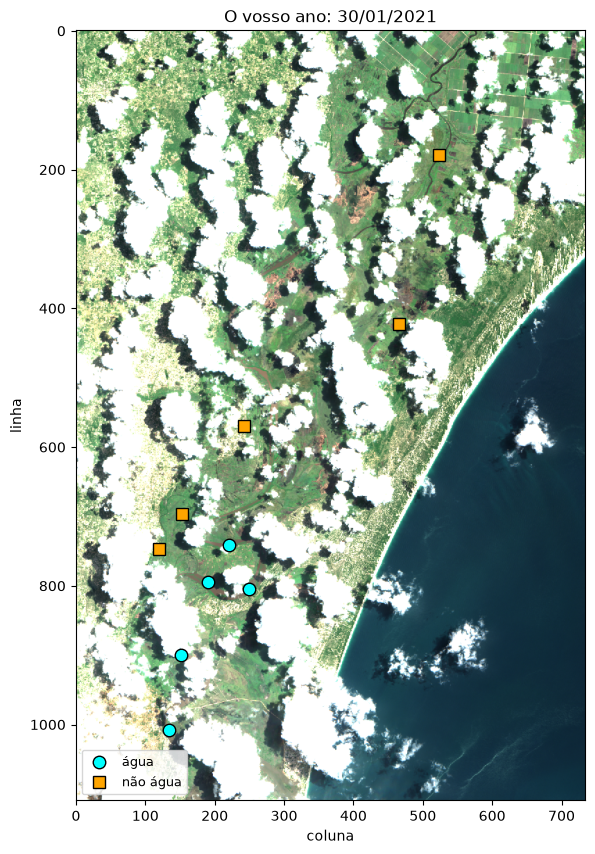

In [2]:
ANO = 2021          # o ano do vosso par
if pronto(ANO) and ano_do_par(ANO):
    img = carregar(f"incomati_{ANO}_chuvosa.npz")
    pontos = pontos_da_equipa(ANO)
    ver_imagem(img, f"O vosso ano: {img['dia']}", pontos["agua"], pontos["nao_agua"])

In [3]:
verificar_passo("1.2")      # a verificação: corram sem mudar nada

Certo! A imagem do vosso ano é de 30/01/2021, do satélite Sentinel-2.


## Passo 3 · A tabela dos exemplos

Façam a tabela dos exemplos com os pontos do vosso ano. Na Aula 1 (Passo 4), a imagem chamava-se `cheia`; aqui chama-se `img`.

In [4]:
exemplos = tabela_de_exemplos(img, pontos["agua"], pontos["nao_agua"])
exemplos.head()

,azul,verde,vermelho,nir,swir,rótulo
0,0.054,0.063,0.073,0.037,0.014,1
1,0.054,0.062,0.072,0.038,0.014,1
2,0.052,0.062,0.072,0.037,0.015,1
3,0.053,0.063,0.073,0.037,0.015,1
4,0.053,0.062,0.072,0.039,0.019,1


In [5]:
verificar_passo("1.3")      # a verificação: corram sem mudar nada

Certo! 249 exemplos: 124 de água e 125 de não água.


## Passo 4 · As características e os rótulos

`X` são as 5 bandas (a lista `BANDAS`) e `y` é a coluna `"rótulo"`. Vejam a Aula 1, Passo 6.

In [6]:
X = exemplos[BANDAS]
y = exemplos["rótulo"]

In [7]:
verificar_passo("1.4")      # a verificação: corram sem mudar nada

Certo! X tem as 5 bandas (as características) e y tem os rótulos (as respostas certas).


## Passo 5 · Treinar a árvore

Criem a árvore e treinem-na com `X` e `y`. A verificação mostra a regra que ela aprendeu.

In [8]:
arvore = DecisionTreeClassifier(max_depth=2, random_state=0)
arvore.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in 

In [9]:
verificar_passo("1.5")      # a verificação: corram sem mudar nada

Certo! A árvore foi treinada. Aprendeu esta regra:

|--- swir <= 0.15
|   |--- azul <= 0.05
|   |   |--- NÃO ÁGUA
|   |--- azul >  0.05
|   |   |--- ÁGUA
|--- swir >  0.15
|   |--- NÃO ÁGUA



> **Nota para o facilitador.** A regra aprendida em cada ano (primeira pergunta da árvore): 2024: VERMELHO ≤ 0,023; 2021: SWIR ≤ 0,148; 2022: VERMELHO ≤ 0,043; 2014: SWIR ≤ 0,022; 2025: SWIR ≤ 0,049. Em 2026 era SWIR ≤ 0,04. Em 2021 (água barrenta) o limite do SWIR sobe muito; em 2022 e 2024 a árvore prefere a banda vermelha. Boa conversa para as apresentações.

## Passo 6 · Prever: o mapa da água

Usem a árvore para desenhar o mapa da água do vosso ano (Aula 1, Passo 7).

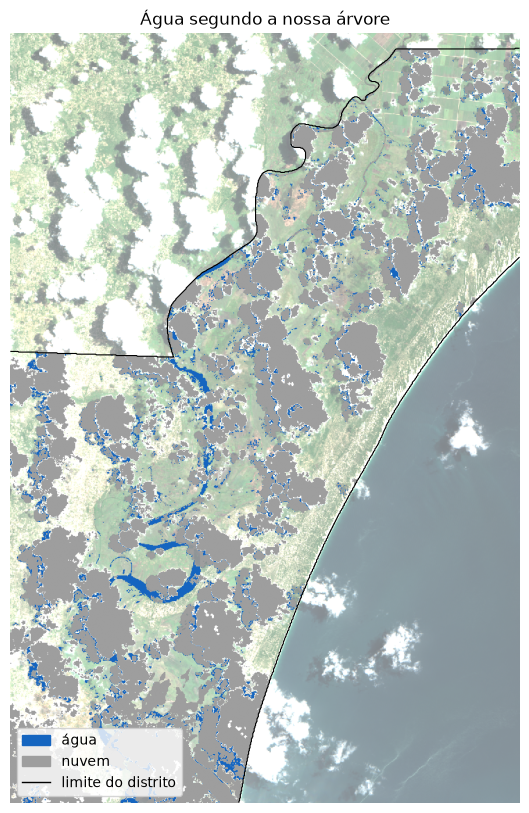

In [10]:
mapa = prever_mapa(arvore, img)
ver_mapa(mapa, img, "Água segundo a nossa árvore")

In [11]:
verificar_passo("1.6")      # a verificação: corram sem mudar nada

Certo! Água no distrito, no vosso ano: 1 782 hectares.


> **Nota para o facilitador.** Hectares de água em cada ano: 2024: 1 444; 2021: 1 782; 2022: 5 819; 2014: 3 740; 2025: 937.

## Para pensar

A árvore aprendeu com exemplos que já tinham a resposta certa. Isto é aprendizagem...

a) supervisionada  
b) não supervisionada  
c) por reforço

In [12]:
resposta = "a"
verificar("P1.a", resposta)

Certo! Aprender com exemplos que já têm a resposta certa (os rótulos) é aprendizagem supervisionada.


A regra que a árvore aprendeu no vosso ano é igual à de 2026 (SWIR ≤ 0,04)?

a) sim, a regra é sempre a mesma  
b) não: muda com a cor da água de cada dia

In [13]:
resposta = "b"
verificar("P1.b", resposta)

Certo! A regra muda com a água: cada imagem tem a sua cor de água, e o modelo aprende a desse dia.


**Para a apresentação:** anotem a regra do vosso ano (a banda e o limite).

## O que aprendemos

- Escreveram sozinhos o caminho do Machine Learning: **exemplos**, **X e y**, **treinar** (fit) e **prever** (predict).
- Cada imagem tem a sua cor de água: o modelo aprende a regra desse dia.

## Guardar os modelos e as separações (só na versão do facilitador)

Ficam nas pastas `modelos_treinados/` e `separacoes/`, ao lado deste notebook. Para usar um modelo noutro notebook: `modelo = joblib.load("modelos_treinados/...joblib")`.

In [14]:
import joblib
os.makedirs("modelos_treinados", exist_ok=True)
os.makedirs("separacoes", exist_ok=True)
joblib.dump(arvore, f"modelos_treinados/pratica1_arvore_{ANO}.joblib")
exemplos.to_csv(f"separacoes/pratica1_exemplos_{ANO}.csv", index=False)
print("Guardado em modelos_treinados/ e separacoes/.")

Guardado em modelos_treinados/ e separacoes/.


## Se aparecer um erro

Leiam a **última linha** da mensagem vermelha.

| A última linha diz | O que fazer |
| --- | --- |
| `NameError: name '...' is not defined` | Saltaram uma célula. Corram as células por ordem, a partir do Passo 1. |
| `FileNotFoundError: Não encontrei ...` | Abram o notebook a partir da pasta `Workshop_2/2_pratica`. |
| `ModuleNotFoundError` | Falta uma biblioteca neste computador: chamem um facilitador. |
| `NotFittedError` ou «O modelo ainda não foi treinado» | Falta treinar o modelo: corram a célula com `.fit(...)`. |
| `SyntaxError` | Falta uma aspa, um parêntese ou uma vírgula. Comparem com o exemplo. |
| «Falta preencher» | Troquem os `...` pela vossa resposta. |

Se nada resultar: menu **Kernel**, depois **Restart Kernel and Run All Cells**.